In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant

pd.set_option('display.max_columns', None)
sns.set_style('whitegrid')

In [2]:
columns = [
    'checking_account', 'duration', 'credit_history', 'purpose', 'credit_amount',
    'savings_account', 'employment_since', 'installment_rate', 'personal_status_sex',
    'other_debtors', 'residence_since', 'property', 'age', 'other_installment_plans',
    'housing', 'existing_credits', 'job', 'num_dependents', 'telephone', 'foreign_worker',
    'target'
]

df = pd.read_csv('../data/german_credit_raw.data', sep=' ', header=None, names=columns)
print(df.shape)
df.head()

(1000, 21)


,checking_account,duration,credit_history,purpose,credit_amount,savings_account,employment_since,installment_rate,personal_status_sex,other_debtors,residence_since,property,age,other_installment_plans,housing,existing_credits,job,num_dependents,telephone,foreign_worker,target
0,A11,6,A34,A43,1169,A65,A75,4,A93,A101,4,A121,67,A143,A152,2,A173,1,A192,A201,1
1,A12,48,A32,A43,5951,A61,A73,2,A92,A101,2,A121,22,A143,A152,1,A173,1,A191,A201,2
2,A14,12,A34,A46,2096,A61,A74,2,A93,A101,3,A121,49,A143,A152,1,A172,2,A191,A201,1
3,A11,42,A32,A42,7882,A61,A74,2,A93,A103,4,A122,45,A143,A153,1,A173,2,A191,A201,1
4,A11,24,A33,A40,4870,A61,A73,3,A93,A101,4,A124,53,A143,A153,2,A173,2,A191,A201,2


In [3]:
df['default'] = df['target'].map({1: 0, 2: 1})
df = df.drop(columns=['target'])

print(df['default'].value_counts())
print(df['default'].value_counts(normalize=True))

default
0    700
1    300
Name: count, dtype: int64
default
0    0.7
1    0.3
Name: proportion, dtype: float64


In [4]:
code_maps = {
    'checking_account': {'A11': '< 0 DM', 'A12': '0-200 DM', 'A13': '>= 200 DM', 'A14': 'no checking account'},
    'credit_history': {'A30': 'no credits/all paid', 'A31': 'all paid at this bank',
                       'A32': 'existing credits paid duly', 'A33': 'delay in past',
                       'A34': 'critical account/other credits'},
    'purpose': {'A40': 'car (new)', 'A41': 'car (used)', 'A42': 'furniture/equipment',
                'A43': 'radio/TV', 'A44': 'domestic appliances', 'A45': 'repairs',
                'A46': 'education', 'A47': 'vacation', 'A48': 'retraining',
                'A49': 'business', 'A410': 'others'},
    'savings_account': {'A61': '< 100 DM', 'A62': '100-500 DM', 'A63': '500-1000 DM',
                        'A64': '>= 1000 DM', 'A65': 'unknown/no savings'},
    'employment_since': {'A71': 'unemployed', 'A72': '< 1 year', 'A73': '1-4 years',
                         'A74': '4-7 years', 'A75': '>= 7 years'},
    'personal_status_sex': {'A91': 'male: divorced/separated', 'A92': 'female: divorced/separated/married',
                            'A93': 'male: single', 'A94': 'male: married/widowed', 'A95': 'female: single'},
    'other_debtors': {'A101': 'none', 'A102': 'co-applicant', 'A103': 'guarantor'},
    'property': {'A121': 'real estate', 'A122': 'building society savings/life insurance',
                 'A123': 'car or other', 'A124': 'unknown/no property'},
    'other_installment_plans': {'A141': 'bank', 'A142': 'stores', 'A143': 'none'},
    'housing': {'A151': 'rent', 'A152': 'own', 'A153': 'for free'},
    'job': {'A171': 'unemployed/unskilled non-resident', 'A172': 'unskilled resident',
            'A173': 'skilled employee/official', 'A174': 'management/self-employed/highly qualified'},
    'telephone': {'A191': 'none', 'A192': 'yes, registered'},
    'foreign_worker': {'A201': 'yes', 'A202': 'no'},
}

for col, mapping in code_maps.items():
    df[col] = df[col].map(mapping)

# Safety check: any NaN here means a code failed to map
print("Missing values after decoding:", df.isna().sum().sum())
df.head()

Missing values after decoding: 0


,checking_account,duration,credit_history,purpose,credit_amount,savings_account,employment_since,installment_rate,personal_status_sex,other_debtors,residence_since,property,age,other_installment_plans,housing,existing_credits,job,num_dependents,telephone,foreign_worker,default
0,< 0 DM,6,critical account/other credits,radio/TV,1169,unknown/no savings,>= 7 years,4,male: single,none,4,real estate,67,none,own,2,skilled employee/official,1,"yes, registered",yes,0
1,0-200 DM,48,existing credits paid duly,radio/TV,5951,< 100 DM,1-4 years,2,female: divorced/separated/married,none,2,real estate,22,none,own,1,skilled employee/official,1,none,yes,1
2,no checking account,12,critical account/other credits,education,2096,< 100 DM,4-7 years,2,male: single,none,3,real estate,49,none,own,1,unskilled resident,2,none,yes,0
3,< 0 DM,42,existing credits paid duly,furniture/equipment,7882,< 100 DM,4-7 years,2,male: single,guarantor,4,building society savings/life insurance,45,none,for free,1,skilled employee/official,2,none,yes,0
4,< 0 DM,24,delay in past,car (new),4870,< 100 DM,1-4 years,3,male: single,none,4,unknown/no property,53,none,for free,2,skilled employee/official,2,none,yes,1


In [5]:
# Check 'female' first: the string 'male' is a substring of 'female'
df['sex'] = df['personal_status_sex'].apply(lambda x: 'female' if 'female' in x else 'male')
df['sex'].value_counts()

sex
male      690
female    310
Name: count, dtype: int64

In [6]:
df.to_csv('../data/german_credit_clean.csv', index=False)
print(df.shape)

(1000, 22)


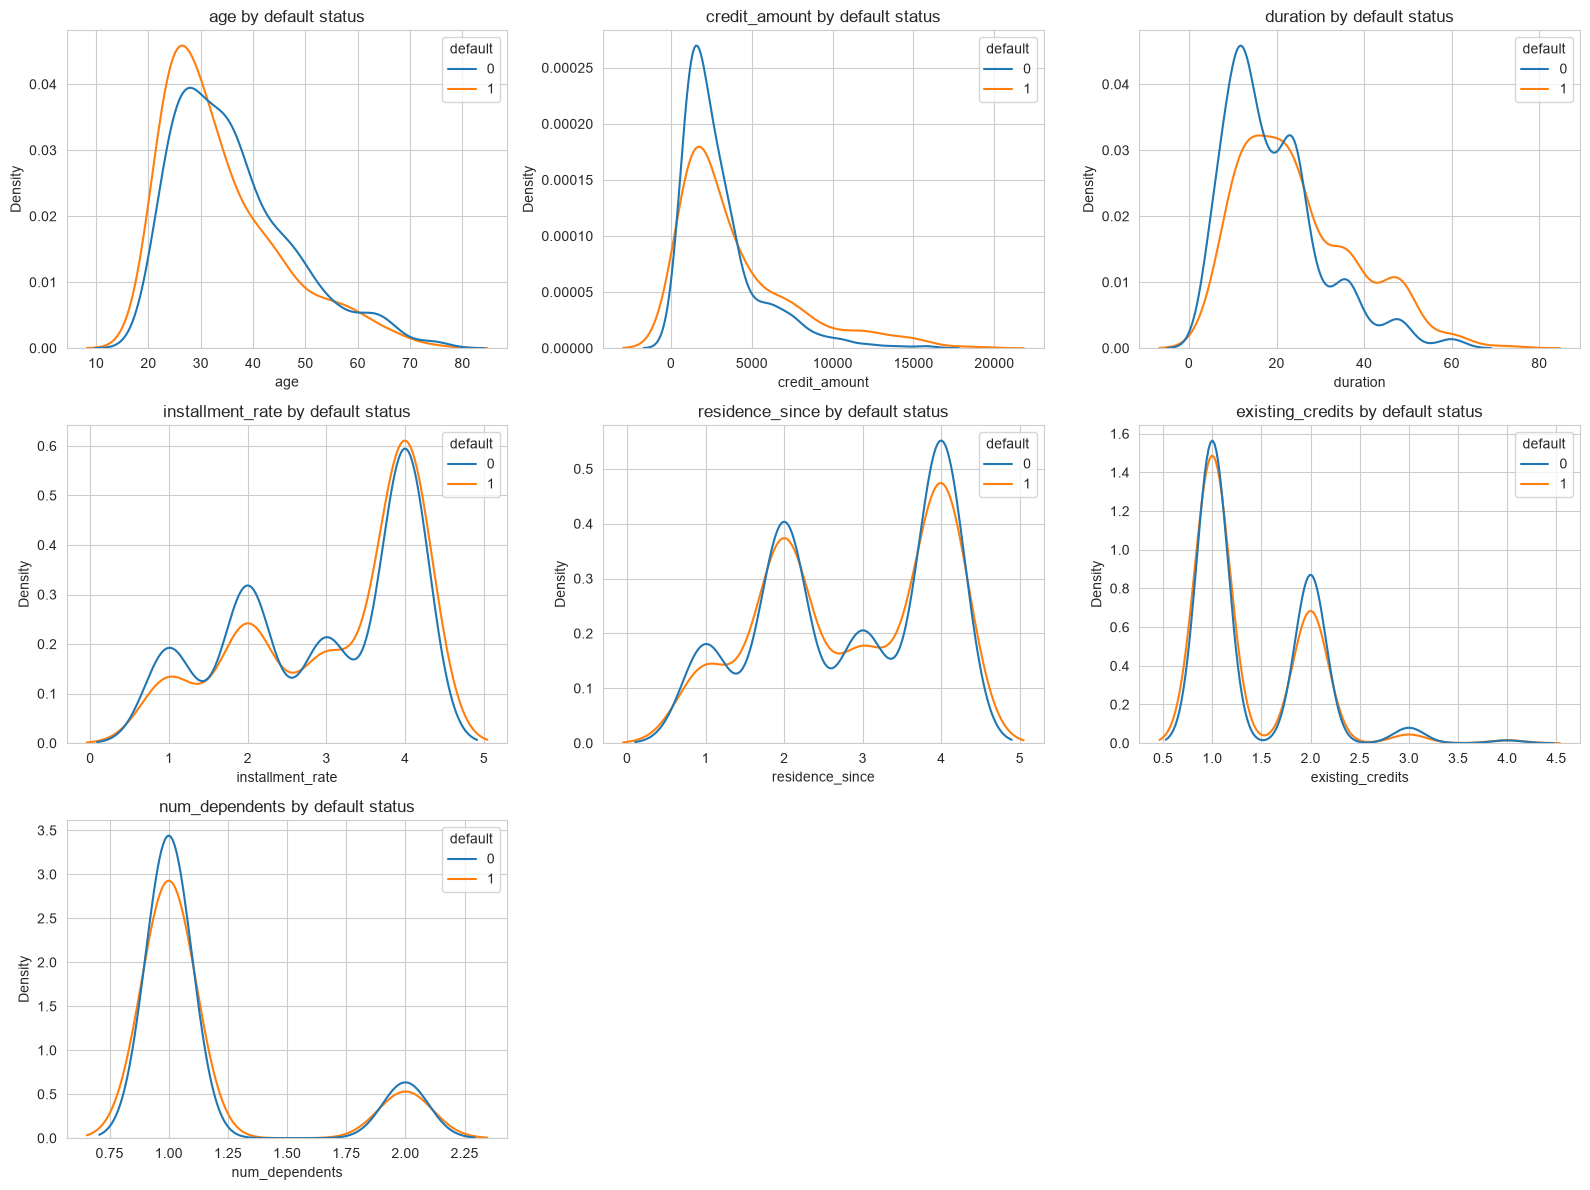

In [7]:
numeric_cols = ['age', 'credit_amount', 'duration', 'installment_rate',
                'residence_since', 'existing_credits', 'num_dependents']

fig, axes = plt.subplots(3, 3, figsize=(16, 12))
axes = axes.flatten()

for i, col in enumerate(numeric_cols):
    sns.kdeplot(data=df, x=col, hue='default', ax=axes[i], common_norm=False)
    axes[i].set_title(f'{col} by default status')

for j in range(len(numeric_cols), len(axes)):
    axes[j].set_visible(False)   # hide the two unused panels

plt.tight_layout()
plt.savefig('../reports/figures/numeric_distributions.png', dpi=100)
plt.show()

In [8]:
for col in numeric_cols:
    good = df[df['default'] == 0][col]
    bad = df[df['default'] == 1][col]
    t_stat, p_val = stats.ttest_ind(good, bad, equal_var=False)
    print(f"{col}: t={t_stat:.3f}, p={p_val:.4f} {'***' if p_val < 0.05 else ''}")

age: t=2.907, p=0.0038 ***
credit_amount: t=-4.264, p=0.0000 ***
duration: t=-6.470, p=0.0000 ***
installment_rate: t=-2.326, p=0.0203 ***
residence_since: t=-0.094, p=0.9250 
existing_credits: t=1.472, p=0.1416 
num_dependents: t=0.095, p=0.9240 


In [9]:
categorical_cols = ['checking_account', 'credit_history', 'purpose', 'savings_account',
                    'employment_since', 'other_debtors', 'property', 'other_installment_plans',
                    'housing', 'job', 'telephone', 'foreign_worker', 'sex']

chi2_results = []
for col in categorical_cols:
    contingency = pd.crosstab(df[col], df['default'])
    chi2, p, dof, expected = stats.chi2_contingency(contingency)
    chi2_results.append({'feature': col, 'chi2': chi2, 'p_value': p, 'dof': dof})

chi2_df = pd.DataFrame(chi2_results).sort_values('p_value')
chi2_df

,feature,chi2,p_value,dof
0,checking_account,123.720944,1.218902e-26,3
1,credit_history,61.691397,1.279187e-12,4
3,savings_account,36.098928,2.761214e-07,4
6,property,23.719551,2.858442e-05,3
8,housing,18.199842,1.116747e-04,2
2,purpose,33.356447,1.157491e-04,9
4,employment_since,18.368274,1.045452e-03,4
7,other_installment_plans,12.839188,1.629318e-03,2
11,foreign_worker,5.821576,1.583075e-02,1
12,sex,5.348516,2.073991e-02,1


In [10]:
vif_data = add_constant(df[numeric_cols].copy())

vif_df = pd.DataFrame({
    'feature': vif_data.columns,
    'VIF': [variance_inflation_factor(vif_data.values, i) for i in range(vif_data.shape[1])]
})
vif_df = vif_df[vif_df['feature'] != 'const'].sort_values('VIF', ascending=False)
vif_df

,feature,VIF
2,credit_amount,1.994152
3,duration,1.857215
4,installment_rate,1.227527
1,age,1.121527
5,residence_since,1.082781
6,existing_credits,1.036226
7,num_dependents,1.030099


In [11]:
old = pd.read_csv('../data/german_credit_clean_backup.csv')
new = pd.read_csv('../data/german_credit_clean.csv')
print("Identical to backup:", old.equals(new))

Identical to backup: True
